In [45]:
# Librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## Data preparation

Check if the missing values are presented in the features.
If there are missing values:
- For categorical features, replace them with 'NA'
- For numerical features, replace with with 0.0


In [12]:
df = pd.read_csv('04-evaluation/course_lead_scoring_2026.csv')
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
num_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 
            'lead_score', 'converted']
for col in cat_cols:
    df[col] = df[col].fillna('NA')
for col in num_cols:
    df[col] = df[col].fillna(0.0)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Split the data into 3 parts with these exact calls:

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
print(f'Numero registros total     : {len(df)}')
print(f'Numero registros full-train: {len(df_full_train)}')
print(f'Numero registros train     : {len(df_train)}')
print(f'Numero registros val       : {len(df_val)}')
print(f'Numero registros test      : {len(df_test)}')

Numero registros total     : 5000
Numero registros full-train: 4000
Numero registros train     : 3000
Numero registros val       : 1000
Numero registros test      : 1000


## Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
- Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score
- number_of_courses_viewed
- interaction_count
- annual_income


In [21]:
print(f"ROC AUC for lead_score: {roc_auc_score(df_train['converted'], df_train['lead_score'])}")
print(f"ROC AUC for number_of_courses_viewed: {roc_auc_score(df_train['converted'], df_train['number_of_courses_viewed'])}")
print(f"ROC AUC for interaction_count: {roc_auc_score(df_train['converted'], df_train['interaction_count'])}")
print(f"ROC AUC for annual_income: {roc_auc_score(df_train['converted'], df_train['annual_income'])}")

ROC AUC for lead_score: 0.7882254810906102
ROC AUC for number_of_courses_viewed: 0.7229894623989618
ROC AUC for interaction_count: 0.7649203047563227
ROC AUC for annual_income: 0.6081977776250831


## Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`

What's the AUC of this model on the validation dataset? (round to 3 digits)
- 0.532
- 0.632
- 0.732
- 0.832

In [24]:
# Splits y
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [27]:
# DictVectorizer
dv = DictVectorizer(sparse=False)
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 
            'lead_score']
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

# Logistic Model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Predict
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
print(f'AUC for model {roc_auc_score(y_val, y_pred):.3f}')

AUC for model 0.732


## Question 3: Precision and Recall

Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3

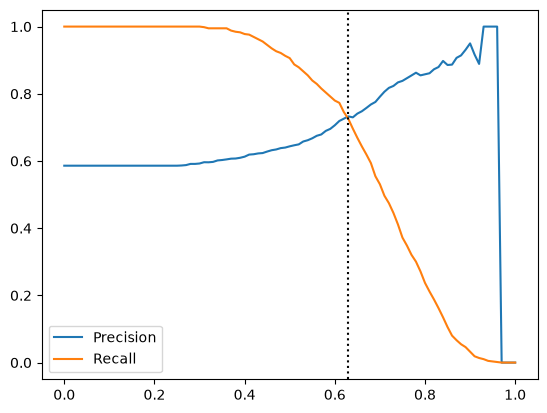

In [38]:
thresholds = np.linspace(0.0, 1.0, 101)
p_score = []
r_score = []
for threshold in thresholds:
    y = (y_pred >= threshold).astype(int)
    p_score.append(precision_score(y_val, y))
    r_score.append(recall_score(y_val, y))

plt.plot(thresholds, p_score, label='Precision')
plt.plot(thresholds, r_score, label='Recall')
plt.axvline(0.63, c='black', ls=':')
plt.legend()

## Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 ⋅ \frac{P \cdot R}{P + R}$$

Where P is precision and R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81


In [44]:
thresholds = np.linspace(0.0, 1.0, 101)
f1_scores = []
for threshold in thresholds:
    y = (y_pred >= threshold).astype(int)
    f1_scores.append(f1_score(y_val, y))

f1_scores = np.array(f1_scores)
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Mejor umbral: {best_threshold:.2f}")
print(f"Mejor F1-score: {best_f1:.4f}")

Mejor umbral: 0.41
Mejor F1-score: 0.7576


## Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

`KFold(n_splits=5, shuffle=True, random_state=1)`

- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060


In [50]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    # Split kfold
    train = df_full_train.iloc[train_idx]
    val = df_full_train.iloc[val_idx]
    y_t = train.converted.values
    y_v = val.converted.values
    # DictVectorizer
    dicts = train[categorical + numerical].to_dict(orient='records')   
    dv = DictVectorizer(sparse=False)
    X_t = dv.fit_transform(dicts)
    # Train model
    model = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear')
    model.fit(X_t, y_t)
    # Predict
    dicts = val[categorical + numerical].to_dict(orient='records')
    X_v = dv.transform(dicts)
    y_pred = model.predict_proba(X_v)[:, 1]

    auc = roc_auc_score(y_v, y_pred)
    scores.append(auc)

print(f'Mean AUC: {np.mean(scores):.3f}')
print(f'Stdv AUC: {np.std(scores):.3f}')

Mean AUC: 0.732
Stdv AUC: 0.007


## Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following C values: [0.000001, 0.001, 1]
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [52]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
for c in [0.000001, 0.001, 1.0]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        # Split kfold
        train = df_full_train.iloc[train_idx]
        val = df_full_train.iloc[val_idx]
        y_t = train.converted.values
        y_v = val.converted.values
        # DictVectorizer
        dicts = train[categorical + numerical].to_dict(orient='records')   
        dv = DictVectorizer(sparse=False)
        X_t = dv.fit_transform(dicts)
        # Train model
        model = LogisticRegression(C=c, max_iter=1000, solver='liblinear')
        model.fit(X_t, y_t)
        # Predict
        dicts = val[categorical + numerical].to_dict(orient='records')
        X_v = dv.transform(dicts)
        y_pred = model.predict_proba(X_v)[:, 1]

        auc = roc_auc_score(y_v, y_pred)
        scores.append(auc)

    print(f'For C = {c:.6f}, mean AUC: {np.mean(scores):.3f}, stdv AUC: {np.std(scores):.3f}')

For C = 0.000001, mean AUC: 0.617, stdv AUC: 0.019
For C = 0.001000, mean AUC: 0.749, stdv AUC: 0.010
For C = 1.000000, mean AUC: 0.732, stdv AUC: 0.007
